# IEOR4500 — Project 4
## Optimization: Convex Portfolio Selection and Nonconvex Model Fitting


### Objective of this project

Apply and **systematically compare multiple optimization algorithms** under a fixed iteration budget. Your goal is to achieve the **lowest valid objective value** after the prescribed number of iterations. You must also analyze convergence, hyperparameter sensitivity, computation, and feasibility.

You will solve two problems:

1. **Convex portfolio optimization** with long-only and fully invested constraints.
2. **Nonconvex optimization** arising from a small, fixed neural-network prediction model.

**Implementation requirement:** Your team must implement **at least one complete optimization algorithm from scratch**. For this project, you are required to implement **Projected Gradient Descent (PGD)** for Problem 1, including its parameter update and projection. You may use NumPy/PyTorch for arrays, automatic differentiation, and linear algebra, but a built-in optimizer step followed by projection **does not count** as the required manual PGD implementation. Additional custom implementations are welcome.

For the remaining experiments, you are encouraged to use appropriate **built-in optimization methods**. You are **not** expected to reimplement all standard optimizers.

### Rules for fair comparisons

- Use the **provided data, objectives, constraints, and initial parameters** unchanged for every algorithm. Do not modify the problem to obtain a smaller objective value.
- You may tune optimization settings: learning rates, step-size schedules, momentum coefficients, minibatch sizes, line-search settings, penalty parameters, and solver options.
- **Score the original objective**, not a penalized surrogate or an individual minibatch loss. Record the original objective at the specified checkpoints. For the portfolio problem, compare the projected first-order methods under the fixed-iteration budget; use the SciPy constrained solver primarily as an accuracy/reference benchmark and the penalty method as a feasibility diagnostic.
- For **Problem 1**, a candidate is feasible only if $w_i\ge -10^{-6}$ for all $i$ and $|\sum_i w_i-1|\le10^{-6}$. An infeasible candidate cannot be ranked as a valid portfolio solution, even if its objective value is lower.
- **Iteration budgets:** at most **100 optimization iterations** for Problem 1, and at most **200 parameter-update iterations** for Problem 2. If an algorithm converges early, report its final result and the actual number of iterations.
- One iteration is **not equally expensive** for all algorithms. In addition to the iteration-based comparisons, report wall-clock time and objective/gradient evaluation counts where accessible. Some line searches and L-BFGS steps perform multiple evaluations.
- For standard first-order methods (e.g., SGD, Momentum, AdaGrad, and Adam), report the objective value after the specified number of iterations. For L-BFGS and other built-in quasi-Newton solvers, you may use their default or tuned iteration and line-search settings. Since a single iteration may involve multiple objective and gradient evaluations, report the number of iterations (`nit`), function evaluations (`nfev`), and gradient evaluations (`njev`) when available, or the number of closure evaluations for PyTorch L-BFGS. Also report the runtime to help compare computational efficiency across methods.
- All methods must start from the prescribed initialization. For stochastic methods, use reproducible random seeds and explain how minibatches are sampled.
- Do **not** add unrequested weight decay or alter the prescribed regularization term. A different training objective is not a valid comparison.

**Algorithm coverage:** The tasks below specify the methods/approaches that **every team is expected to attempt**. Do not stop after obtaining a good result with only two or three methods. Document unsuccessful or unstable tuning trials as well as successful ones.

**Tuning:** Conduct a meaningful hyperparameter search for each method, not just one untuned run. Report the settings tried and identify the best configuration under the stated budget.

In [156]:
import time
import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.optimize import minimize

np.set_printoptions(precision=5, suppress=True)
print('NumPy:', np.__version__)
print('PyTorch:', torch.__version__)

NumPy: 1.26.4
PyTorch: 2.15.0


---
# Problem 1 — Convex Portfolio Optimization

### Background

A portfolio manager allocates capital to $n$ risky assets. Let $\mu\in\mathbb R^n$ be their estimated annualized expected returns and let $\Sigma\in\mathbb R^{n\times n}$ be the annualized covariance matrix. We balance expected return and variance by minimizing

$$
\boxed{F(w)=-\mu^\top w+\frac{\gamma}{2}w^\top\Sigma w}
$$

subject to

$$
w_i\ge0 \quad(i=1,\ldots,n),\qquad \sum_{i=1}^n w_i=1.
$$

This is a **convex quadratic optimization problem**. We use the same fixed simulated return data for every team and every algorithm. The synthetic data avoid external downloading or changing market histories.

**Fixed problem:** 60 assets, 504 daily observations, and $\gamma=8$. The provided functions define the exact objective and gradient to use.

In [157]:
# Fixed portfolio data — do not modify.
rng_p = np.random.default_rng(4500)
T, n_assets, n_factors = 504, 60, 5
true_mu = np.clip(rng_p.normal(0.075, 0.03, size=n_assets), 0.015, 0.14)

factors = rng_p.standard_normal((T, n_factors))
factors -= factors.mean(axis=0)
loadings = rng_p.normal(size=(n_factors, n_assets)) / np.sqrt(n_factors)
idiosyncratic = rng_p.standard_normal((T, n_assets))
idiosyncratic -= idiosyncratic.mean(axis=0)

returns = true_mu[None, :] / 252 + 0.012 * (factors @ loadings) + 0.008 * idiosyncratic
mu = 252 * returns.mean(axis=0)
Sigma = 252 * np.cov(returns, rowvar=False)
gamma = 8.0
w_init = np.ones(n_assets, dtype=float) / n_assets

print(f'{n_assets} assets, {T} observations')
print('Smallest covariance eigenvalue:', np.linalg.eigvalsh(Sigma).min())

60 assets, 504 observations
Smallest covariance eigenvalue: 0.007134254176514595


In [158]:
# The original objective and its gradient are fixed for all methods.
def portfolio_objective_np(w):
    w = np.asarray(w, dtype=float)
    return float(-mu @ w + 0.5 * gamma * (w @ Sigma @ w))

def portfolio_gradient_np(w):
    w = np.asarray(w, dtype=float)
    return -mu + gamma * (Sigma @ w)

mu_t = torch.tensor(mu, dtype=torch.float64)
Sigma_t = torch.tensor(Sigma, dtype=torch.float64)

def portfolio_objective_torch(w):
    return -(mu_t @ w) + 0.5 * gamma * (w @ Sigma_t @ w)

def portfolio_violations(w):
    w = np.asarray(w, dtype=float)
    return {
        'nonnegative_violation': float(np.maximum(-w, 0.0).max()),
        'budget_violation': float(abs(w.sum() - 1.0)),
    }

def portfolio_valid(w, tolerance=1e-6):
    return max(portfolio_violations(w).values()) <= tolerance

print('Initial portfolio objective:', portfolio_objective_np(w_init))
print('Initial constraint violations:', portfolio_violations(w_init))
assert np.isclose(portfolio_objective_torch(torch.tensor(w_init)).item(),
                  portfolio_objective_np(w_init), atol=1e-12)

Initial portfolio objective: -0.06724570955531893
Initial constraint violations: {'nonnegative_violation': 0.0, 'budget_violation': 0.0}


### Task 1 — Required algorithm comparisons (100 iterations)

**Every team must attempt all of the following:**

1. **Manual Projected Gradient Descent (PGD).** Implement the gradient update and Euclidean projection onto the feasible set yourselves. This is the **required from-scratch optimizer**.
2. **Projected Momentum.** Use a built-in optimizer (e.g., PyTorch SGD with momentum), combined with the appropriate projection.
3. **Projected Adam.** Use built-in Adam, combined with the appropriate projection.
4. **A built-in constrained solver (reference benchmark).** Use `scipy.optimize.minimize` with a method supporting the required constraints (e.g., `SLSQP`). This demonstrates what a dedicated constrained solver can achieve; report its iterations and evaluations, but do not treat it as a fair substitute for tuning projected first-order methods.
5. **A squared-penalty approach (feasibility comparison).** Use a standard unconstrained optimizer on a penalized objective. Report the **original** objective and constraint violations; discuss whether the penalty solution is feasible under the given tolerance.

**Additional reference (encouraged, but not a substitute for any of the above):** Use CVXPY or another convex QP solver to estimate a reference optimal value. Distinguish this solver benchmark from fixed-iteration method comparisons.

**Experiment requirements**

- Start all algorithms at the given $w_0=(1/n,\ldots,1/n)$.
- Tune learning rates/schedules, momentum or adaptive settings, solver settings, and penalty parameters as appropriate.
- Report the **original objective value at iterations 0, 20, 50, and 100**, or the final value if a solver terminates early. Report feasibility, computation time, and evaluation counts when available.
- Compare **PGD, projected Momentum, and projected Adam** by their **feasible original objective values** at the fixed iteration checkpoints. Report the dedicated SciPy solver separately as a numerical reference; include the penalty method to analyze constraint satisfaction. Show violations for *all* approaches.
- Plot objective versus iteration, clearly identifying infeasible iterates (if any). Explain meaningful differences in convergence and computational cost.

**You must write the optimization code and projection yourselves for the manual PGD experiment.**

In [159]:
# TODO — Problem 1
# Implement and tune every required method listed above.
# Record results and checkpoint objective values for each method.
# Include constraint violations and objective/gradient evaluation counts.

portfolio_results = {}

---
# Problem 2 — Smooth Nonconvex Optimization: A Fixed Neural Network

### Background (no prior neural-network knowledge required)

A small prediction model maps eight market features $x\in\mathbb R^8$ to a predicted short-horizon financial signal. The model is a **two-layer neural network**, but **you do not need to know how neural networks are trained** for this project: the prediction formula, loss function, and complete PyTorch implementation are already provided.

Treat the entire model as a **fixed differentiable function of a parameter vector** $\theta\in\mathbb R^{241}$. Your task is only to optimize $\theta$.

With hidden width $m=24$, define

$$
\widehat y_\theta(x)=a^\top\tanh(Wx+b)+c,
$$

where $W\in\mathbb R^{24\times8}$, $b,a\in\mathbb R^{24}$, $c\in\mathbb R$, and $\theta$ concatenates all these parameters. The activation $\tanh$ is applied coordinate-wise.

Given fixed observations $(x_i,y_i)$, minimize

$$
\boxed{L(\theta)=\frac1N\sum_{i=1}^N(\widehat y_\theta(x_i)-y_i)^2
+\frac\lambda2\|\theta\|_2^2},\qquad\lambda=10^{-4}.
$$

This function is **smooth but generally nonconvex** in $\theta$. Autograd computes the gradient; you do **not** need to derive derivatives through the network.

**Fixed problem:** $N=512$ observations; eight features; 241 parameters. Do not change the data, model, objective, coefficient $\lambda$, or initialization. You may change the optimizer and its settings.

In [160]:
# Fixed nonconvex data and initialization — do not modify.
rng_nn = np.random.default_rng(4501)
N, d_in, hidden_width = 512, 8, 24
X_np = rng_nn.normal(size=(N, d_in))
u = rng_nn.normal(size=d_in)
v = rng_nn.normal(size=d_in)
y_np = (1.25 * np.tanh(X_np @ u / np.sqrt(d_in))
        + 0.6 * np.sin(X_np @ v / np.sqrt(d_in))
        + 0.25 * X_np[:, 0] * X_np[:, 1]
        + 0.08 * rng_nn.normal(size=N))

X_train = torch.tensor(X_np, dtype=torch.float64)
y_train = torch.tensor(y_np, dtype=torch.float64)
lam = 1e-4

rng_init = np.random.default_rng(4502)
W_init = rng_init.normal(scale=0.24, size=(hidden_width, d_in))
b_init = np.zeros(hidden_width)
a_init = rng_init.normal(scale=0.18, size=hidden_width)
c_init = np.array([0.0])
theta_initial_np = np.concatenate([
    W_init.reshape(-1), b_init, a_init, c_init
])
theta_initial = torch.tensor(theta_initial_np, dtype=torch.float64)

assert theta_initial.numel() == 241
print('Training observations:', N)
print('Trainable parameters:', theta_initial.numel())

Training observations: 512
Trainable parameters: 241


In [161]:
# Fully specified model and objective: treat L(theta) as a black box.
# There is no need to use torch.nn, construct a model, or derive gradients.
def nn_predictions(theta, X):
    m, d = hidden_width, d_in
    W = theta[:m*d].reshape(m, d)
    b = theta[m*d:m*d + m]
    a = theta[m*d + m:m*d + 2*m]
    c = theta[-1]
    return torch.tanh(X @ W.T + b) @ a + c

def nn_objective(theta, X=X_train, y=y_train):
    predictions = nn_predictions(theta, X)
    mse = ((predictions - y) ** 2).mean()
    regularizer = (lam / 2) * (theta ** 2).sum()
    return mse + regularizer

def fresh_theta():
    """Start a new optimizer at exactly the prescribed parameter vector."""
    return theta_initial.detach().clone().requires_grad_(True)

@torch.no_grad()
def nn_score(theta):
    """Evaluate the ORIGINAL FULL-DATA objective for reporting."""
    return float(nn_objective(theta, X_train, y_train).item())

print('Initial nonconvex objective:', nn_score(fresh_theta()))
assert abs(nn_score(fresh_theta()) - nn_score(fresh_theta())) < 1e-12

Initial nonconvex objective: 1.0540702245853104


### Task 2 — Required algorithm comparisons (200 parameter updates)

**Every team must attempt all of the following:**

1. **Full-batch Gradient Descent**, using `torch.optim.SGD` with momentum set to zero.
2. **Mini-batch SGD**, using the same objective but stochastic batches of observations.
3. **SGD with Momentum**, using `torch.optim.SGD(momentum=...)`.
4. **AdaGrad**, using `torch.optim.Adagrad`.
5. **Adam**, using `torch.optim.Adam`.
6. **PyTorch L-BFGS**, using `torch.optim.LBFGS` and a correctly defined closure.
7. **SciPy BFGS**, using `scipy.optimize.minimize(method='BFGS')` with an appropriate objective and gradient interface.

All of these algorithms can be used on the supplied parameter vector `theta` without needing a neural-network API. You may additionally try a manually implemented method, Newton-type methods, alternative step-size schedules, or other reasonable optimizers, but those additions do not replace the required comparisons.

**Experiment requirements**

- For **every run**, initialize from `fresh_theta()`. For SciPy, use the same initial numerical vector `theta_initial_np`.
- Tune hyperparameters systematically: learning rate and schedule, momentum coefficient, minibatch size, L-BFGS history/line search, or solver tolerances as applicable.
- Use a budget of **200 parameter updates/optimizer iterations**. Report the **full training objective** at iterations/updates **0, 20, 50, 100, and 200**, with time and function/gradient evaluation counts when available. If a solver stops early, record the stopping iteration and carry its final value forward for the comparison.
- For mini-batch methods, use a fixed random seed to ensure reproducibility. At each checkpoint, evaluate and report the original objective function using the **entire training dataset**, rather than the loss computed on the current mini-batch.
- For L-BFGS and other built-in quasi-Newton solvers, you may use their default or tuned iteration and line-search settings. Since a single iteration may involve multiple objective and gradient evaluations, report the number of iterations (`nit`), function evaluations (`nfev`), and gradient evaluations (`njev`) when available, or the number of closure evaluations for PyTorch L-BFGS. Also report the runtime to help compare computational efficiency across methods.
- The objective *already includes* $\frac\lambda2\|\theta\|^2$. Keep optimizer `weight_decay=0` to avoid changing or double-counting the prescribed regularizer.
- Explain how optimizer choice and learning-rate tuning affect the **objective after a fixed update budget**. Compare runtime and evaluation counts separately.

**You do not need to change or understand the internal structure of `nn_predictions`.** Treat `nn_objective(theta)` as the provided differentiable objective and let PyTorch compute its derivatives.

In [162]:
# TODO — Problem 2
# Use nn_objective(theta) as the optimization objective.
# Use fresh_theta() at the start of every experiment.
# Implement and tune every required method listed above.
# Evaluate the original full objective using nn_score(theta).


import pandas as pd
from itertools import product

CHECKPOINTS = (0, 20, 50, 100, 200)
BUDGET = 200
BATCH_SEED = 42

nn_results = {}

In [163]:
from time import perf_counter

first_order_results = {}
tuning_history = []

### First-Order Optimization 

We use a shared optimization pipeline for full-batch GD, mini-batch SGD, Momentum, AdaGrad, and Adam to avoid repeating code across the five methods. Each experiment starts from the same given initialization and runs for 200 parameter updates. Weight decay was set to 0 since regularization is already included in the original objective function.

In [164]:
def make_optimizer(
    method,
    theta,
    lr,
    momentum=0.9,
    betas=(0.9, 0.999),
    initial_accumulator=0.0
):
    if method in ("GD", "Mini-batch SGD"):
        return torch.optim.SGD(
            [theta], lr=lr, weight_decay=0
        )

    elif method == "Momentum":
        return torch.optim.SGD(
            [theta], lr=lr, momentum=momentum, weight_decay=0
        )

    elif method == "AdaGrad":
        return torch.optim.Adagrad(
            [theta], lr=lr,
            initial_accumulator_value=initial_accumulator,
            weight_decay=0
        )

    elif method == "Adam":
        return torch.optim.Adam(
            [theta], lr=lr, betas=betas, weight_decay=0
        )

    raise ValueError(f"Unknown optimizer: {method}")

In [165]:
def run_first_order(
    method,
    lr,
    batch_size=64,
    momentum=0.9,
    betas=(0.9, 0.999),
    initial_accumulator=0.0,
    schedule="constant"
):
    wall_start = perf_counter()
    theta = fresh_theta()

    optimizer = make_optimizer(
        method, theta, lr,
        momentum=momentum,
        betas=betas,
        initial_accumulator=initial_accumulator
    )

    generator = torch.Generator().manual_seed(BATCH_SEED)

    scheduler = None
    if schedule == "cosine":
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=BUDGET
        )

    history = [nn_score(theta)]
    time_history = [0.0]

    runtime = 0.0
    nfev = 0
    njev = 0
    nit = 0
    status = "completed"

    for update in range(1, BUDGET + 1):
        start = perf_counter()

        optimizer.zero_grad()

        if method == "Mini-batch SGD":
            idx = torch.randperm(
                len(X_train), generator=generator
            )[:batch_size]

            loss = nn_objective(
                theta, X_train[idx], y_train[idx]
            )
        else:
            loss = nn_objective(theta)

        nfev += 1

        if not torch.isfinite(loss).item():
            runtime += perf_counter() - start
            status = "diverged"
            break

        loss.backward()
        njev += 1

        optimizer.step()
        nit += 1

        if scheduler is not None:
            scheduler.step()

        runtime += perf_counter() - start

        score = nn_score(theta)
        history.append(score)
        time_history.append(runtime)

        if not np.isfinite(score):
            status = "diverged"
            break

    return {
        "method": method,
        "history": history,
        "time_history": time_history,
        "final_objective": history[-1],
        "runtime": runtime,
        "wall_time": perf_counter() - wall_start,
        "nit": nit,
        "nfev": nfev,
        "njev": njev,
        "reporting_evals": len(history),
        "status": status,
        "params": {
            "lr": lr,
            "batch_size": batch_size,
            "momentum": momentum,
            "betas": betas,
            "initial_accumulator": initial_accumulator,
            "schedule": schedule
        }
    }

In [166]:
methods = [
    "GD",
    "Mini-batch SGD",
    "Momentum",
    "AdaGrad",
    "Adam"
]

for method in methods:
    result = run_first_order(method, lr=0.01)

    print(f"\n{method}")
    print(f"Initial objective: {result['history'][0]:.8f}")
    print(f"Final objective: {result['final_objective']:.8f}")
    print(f"Updates: {result['nit']}")
    print(f"Status: {result['status']}")

    assert result["nit"] == BUDGET
    assert len(result["history"]) == BUDGET + 1
    assert result["nfev"] == result["njev"] == BUDGET
    assert result["status"] == "completed"
    assert np.isfinite(result["final_objective"])
    assert np.isclose(
        result["history"][0],
        nn_score(fresh_theta())
    )


GD
Initial objective: 1.05407022
Final objective: 0.18298966
Updates: 200
Status: completed

Mini-batch SGD
Initial objective: 1.05407022
Final objective: 0.18332562
Updates: 200
Status: completed

Momentum
Initial objective: 1.05407022
Final objective: 0.08680878
Updates: 200
Status: completed

AdaGrad
Initial objective: 1.05407022
Final objective: 0.13877476
Updates: 200
Status: completed

Adam
Initial objective: 1.05407022
Final objective: 0.01814237
Updates: 200
Status: completed


### Coarse Hyperparameter Search

We first conducted a broad grid search over learning rates and optimizer-specific hyperparameters. Each configuration is evaluated using the same initialization and update budget. We then selected the configuration with the lowest full-data objective after 200 updates, keeping track of unsuccessful and divergent trials.

In [167]:
param_grids = {
    "GD": {
        "lr": [0.001, 0.01, 0.05, 0.1, 0.2, 0.4, 0.8]
    },

    "Mini-batch SGD": {
        "lr": [0.003, 0.01, 0.05, 0.1, 0.2, 0.4],
        "batch_size": [16, 32, 64, 128]
    },

    "Momentum": {
        "lr": [0.003, 0.01, 0.05, 0.1, 0.2, 0.4],
        "momentum": [0.5, 0.9, 0.95]
    },

    "AdaGrad": {
        "lr": [0.01, 0.05, 0.1, 0.2, 0.5, 1.0],
        "initial_accumulator": [0.0, 0.1]
    },

    "Adam": {
        "lr": [0.001, 0.005, 0.01, 0.05, 0.1, 0.2],
        "betas": [
            (0.9, 0.999),
            (0.9, 0.99),
            (0.95, 0.999)
        ]
    }
}

In [168]:
def tune_optimizer(method, param_grid, stage="coarse"):
    keys = list(param_grid.keys())

    best_result = None
    best_params = None

    for values in product(*param_grid.values()):
        params = dict(zip(keys, values))

        result = run_first_order(method, **params)

        tuning_history.append({
            "method": method,
            "stage": stage,
            "params": params.copy(),
            "final_objective": result["final_objective"],
            "runtime": result["runtime"],
            "nit": result["nit"],
            "nfev": result["nfev"],
            "njev": result["njev"],
            "status": result["status"]
        })

        valid = (
            result["status"] == "completed"
            and result["nit"] == BUDGET
            and np.isfinite(result["final_objective"])
        )

        if valid and (
            best_result is None
            or result["final_objective"] < best_result["final_objective"]
        ):
            best_result = result
            best_params = params.copy()

    return best_result, best_params

In [169]:
best_configs = {}

tuning_history.clear()
first_order_results.clear()

for method, param_grid in param_grids.items():

    best_result, best_params = tune_optimizer(
        method, param_grid
    )

    if best_result is None:
        print(f"{method}: No stable configurations found")
        continue

    first_order_results[method] = best_result
    best_configs[method] = best_params

    print(f"\n{method}")
    print(f"Best parameters: {best_params}")
    print(f"Final objective: {best_result['final_objective']:.8f}")
    print(f"Runtime: {best_result['runtime']:.6f}s")

print(f"\nTotal trials: {len(tuning_history)}")
coarse_results = first_order_results.copy()
coarse_configs = best_configs.copy()


GD
Best parameters: {'lr': 0.4}
Final objective: 0.02548263
Runtime: 0.253496s

Mini-batch SGD
Best parameters: {'lr': 0.4, 'batch_size': 128}
Final objective: 0.05432085
Runtime: 0.071607s

Momentum
Best parameters: {'lr': 0.2, 'momentum': 0.9}
Final objective: 0.00887018
Runtime: 0.091163s

AdaGrad
Best parameters: {'lr': 0.1, 'initial_accumulator': 0.0}
Final objective: 0.01638051
Runtime: 0.190050s

Adam
Best parameters: {'lr': 0.1, 'betas': (0.9, 0.999)}
Final objective: 0.00728234
Runtime: 0.091825s

Total trials: 79


In [170]:
tuning_df = pd.DataFrame(tuning_history)

for method in methods:

    trials = tuning_df[
        (tuning_df["method"] == method)
        & (tuning_df["status"] == "completed")
    ]

    print(f"\nTop 5 configurations: {method}")

    display(
        trials.nsmallest(5, "final_objective")[
            ["params", "final_objective", "runtime"]
        ].reset_index(drop=True)
    )


Top 5 configurations: GD


,params,final_objective,runtime
0,{'lr': 0.4},0.025483,0.253496
1,{'lr': 0.2},0.056543,0.092772
2,{'lr': 0.1},0.079580,0.086373
3,{'lr': 0.05},0.122739,0.087992
4,{'lr': 0.01},0.182990,0.085134



Top 5 configurations: Mini-batch SGD


,params,final_objective,runtime
0,"{'lr': 0.4, 'batch_size': 128}",0.054321,0.071607
1,"{'lr': 0.2, 'batch_size': 128}",0.061141,0.072822
2,"{'lr': 0.2, 'batch_size': 64}",0.062802,0.067124
3,"{'lr': 0.4, 'batch_size': 32}",0.067132,0.061953
4,"{'lr': 0.2, 'batch_size': 32}",0.073201,0.069513



Top 5 configurations: Momentum


,params,final_objective,runtime
0,"{'lr': 0.2, 'momentum': 0.9}",0.008870,0.091163
1,"{'lr': 0.2, 'momentum': 0.95}",0.009620,0.091859
2,"{'lr': 0.1, 'momentum': 0.95}",0.011215,0.087933
3,"{'lr': 0.1, 'momentum': 0.9}",0.012720,0.090697
4,"{'lr': 0.4, 'momentum': 0.5}",0.013354,0.086145



Top 5 configurations: AdaGrad


,params,final_objective,runtime
0,"{'lr': 0.1, 'initial_accumulator': 0.0}",0.016381,0.190050
1,"{'lr': 0.2, 'initial_accumulator': 0.0}",0.016416,0.088835
2,"{'lr': 0.2, 'initial_accumulator': 0.1}",0.022073,0.092764
3,"{'lr': 0.05, 'initial_accumulator': 0.0}",0.023786,0.128178
4,"{'lr': 0.5, 'initial_accumulator': 0.1}",0.024557,0.197405



Top 5 configurations: Adam


,params,final_objective,runtime
0,"{'lr': 0.1, 'betas': (0.9, 0.999)}",0.007282,0.091825
1,"{'lr': 0.1, 'betas': (0.9, 0.99)}",0.007621,0.091152
2,"{'lr': 0.05, 'betas': (0.9, 0.999)}",0.007885,0.093037
3,"{'lr': 0.05, 'betas': (0.9, 0.99)}",0.008025,0.091221
4,"{'lr': 0.2, 'betas': (0.9, 0.99)}",0.009539,0.098986


In [171]:
unstable_trials = tuning_df[
    tuning_df["status"] != "completed"
]

print(f"Total trials: {len(tuning_df)}")
print(f"Successful trials: {len(tuning_df) - len(unstable_trials)}")
print(f"Unstable trials: {len(unstable_trials)}")

display(
    unstable_trials[
        ["method", "params", "final_objective", "nit", "status"]
    ].reset_index(drop=True)
)

Total trials: 79
Successful trials: 78
Unstable trials: 1


,method,params,final_objective,nit,status
0,GD,{'lr': 0.8},inf,182,diverged


### Hyperparameter Refinement

Based on coarse search results, we refined the search around promising learning rates and optimizer-specific parameters. For GD, divergence at a learning rate of 0.8 gives us a narrower search range. For mini-batch SGD, we explored larger batch sizes and alternative learning rates. We also compared constant learning rates with cosine annealing schedules.

There were 79 coarse trials and 138 refined trials. We kept the best-performing configuration for each optimizer across both stages.

In [172]:
refined_grids = {
    "GD": {
        "lr": [0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6],
        "schedule": ["constant", "cosine"]
    },

    "Mini-batch SGD": {
        "lr": [0.3, 0.4, 0.45, 0.5, 0.6],
        "batch_size": [64, 128, 256],
        "schedule": ["constant", "cosine"]
    },

    "Momentum": {
        "lr": [0.15, 0.2, 0.25, 0.28, 0.3],
        "momentum": [0.85, 0.9, 0.95],
        "schedule": ["constant", "cosine"]
    },

    "AdaGrad": {
        "lr": [0.08, 0.12, 0.14, 0.16, 0.18, 0.2],
        "initial_accumulator": [0.0, 0.01],
        "schedule": ["constant", "cosine"]
    },

    "Adam": {
        "lr": [0.05, 0.075, 0.1, 0.125, 0.15],
        "betas": [
            (0.85, 0.999),
            (0.9, 0.999),
            (0.9, 0.99),
            (0.95, 0.999)
        ],
        "schedule": ["constant", "cosine"]
    }
}

In [173]:
tuning_history[:] = [
    trial for trial in tuning_history
    if trial["stage"] == "coarse"
]

first_order_results = coarse_results.copy()
best_configs = coarse_configs.copy()

for method, param_grid in refined_grids.items():

    previous_objective = first_order_results[method]["final_objective"]

    result, params = tune_optimizer(
        method, param_grid, stage="refined"
    )

    if (
        result is not None
        and result["final_objective"] < previous_objective
    ):
        first_order_results[method] = result
        best_configs[method] = params

    final_objective = first_order_results[method]["final_objective"]

    improvement = (
        (previous_objective - final_objective)
        / previous_objective * 100
    )

    print(f"\n{method}")
    print(f"Best parameters: {best_configs[method]}")
    print(f"Previous objective: {previous_objective:.8f}")
    print(f"Best objective: {final_objective:.8f}")
    print(f"Improvement: {improvement:.2f}%")

print(f"\nTotal tuning trials: {len(tuning_history)}")


GD
Best parameters: {'lr': 0.4}
Previous objective: 0.02548263
Best objective: 0.02548263
Improvement: 0.00%

Mini-batch SGD
Best parameters: {'lr': 0.3, 'batch_size': 256, 'schedule': 'constant'}
Previous objective: 0.05432085
Best objective: 0.04305021
Improvement: 20.75%

Momentum
Best parameters: {'lr': 0.3, 'momentum': 0.9, 'schedule': 'constant'}
Previous objective: 0.00887018
Best objective: 0.00751764
Improvement: 15.25%

AdaGrad
Best parameters: {'lr': 0.14, 'initial_accumulator': 0.0, 'schedule': 'constant'}
Previous objective: 0.01638051
Best objective: 0.01499506
Improvement: 8.46%

Adam
Best parameters: {'lr': 0.05, 'betas': (0.85, 0.999), 'schedule': 'constant'}
Previous objective: 0.00728234
Best objective: 0.00689680
Improvement: 5.29%

Total tuning trials: 217


In [174]:
refinement_rows = []

for method in methods:

    coarse = coarse_results[method]["final_objective"]
    refined = first_order_results[method]["final_objective"]

    refinement_rows.append({
        "Method": method,
        "Coarse objective": coarse,
        "Final objective": refined,
        "Improvement (%)": 100 * (coarse - refined) / coarse,
        "Best parameters": best_configs[method]
    })

refinement_df = pd.DataFrame(refinement_rows)

with pd.option_context("display.max_colwidth", None):
    display(refinement_df)

,Method,Coarse objective,Final objective,Improvement (%),Best parameters
0,GD,0.025483,0.025483,0.000000,{'lr': 0.4}
1,Mini-batch SGD,0.054321,0.043050,20.748278,"{'lr': 0.3, 'batch_size': 256, 'schedule': 'constant'}"
2,Momentum,0.008870,0.007518,15.248170,"{'lr': 0.3, 'momentum': 0.9, 'schedule': 'constant'}"
3,AdaGrad,0.016381,0.014995,8.457939,"{'lr': 0.14, 'initial_accumulator': 0.0, 'schedule': 'constant'}"
4,Adam,0.007282,0.006897,5.294202,"{'lr': 0.05, 'betas': (0.85, 0.999), 'schedule': 'constant'}"


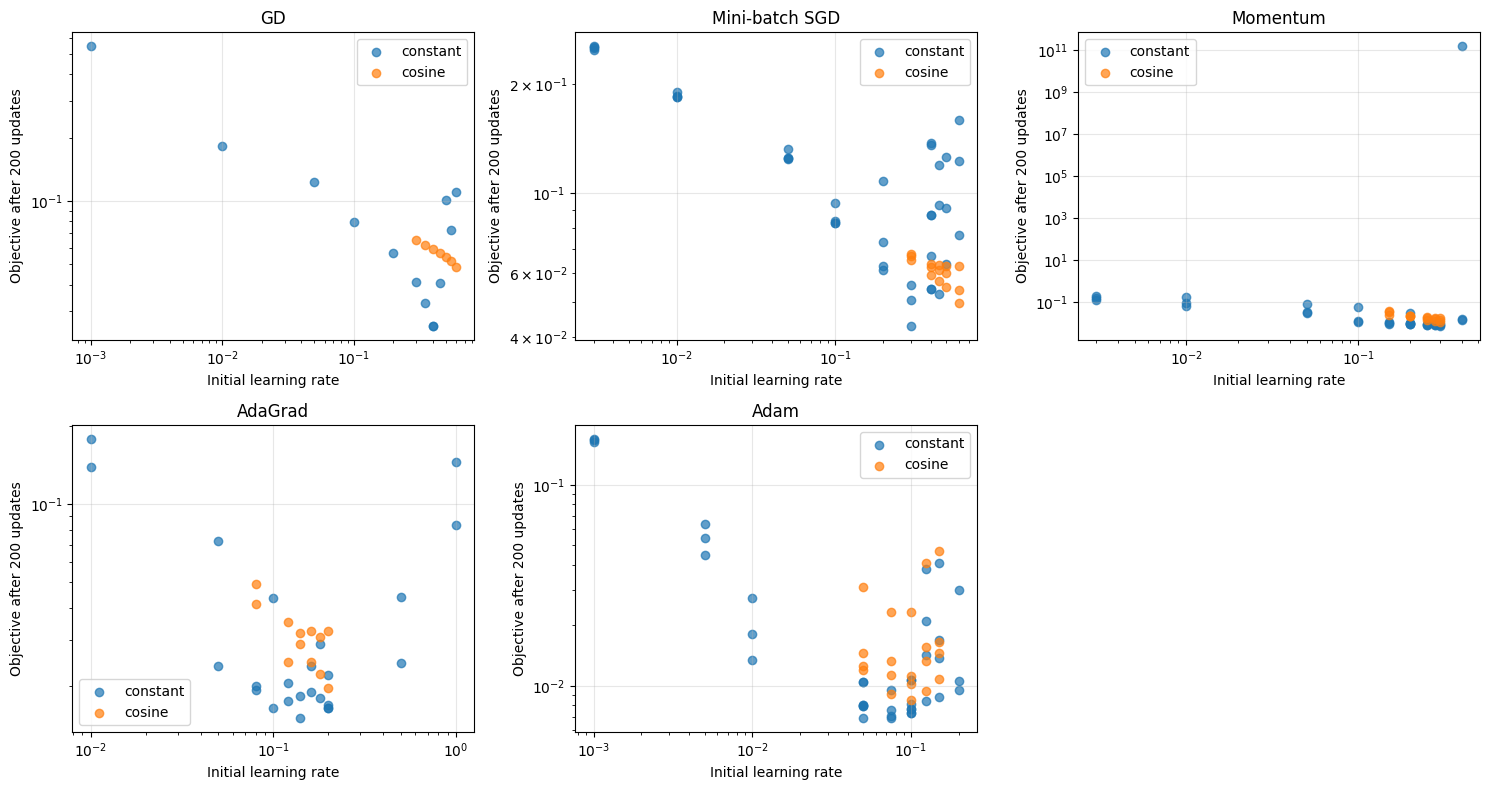

In [175]:
tuning_df = pd.DataFrame(tuning_history)

successful_trials = tuning_df[
    tuning_df["status"] == "completed"
].copy()

successful_trials["lr"] = successful_trials["params"].apply(
    lambda params: params["lr"]
)

successful_trials["schedule"] = successful_trials["params"].apply(
    lambda params: params.get("schedule", "constant")
)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, method in zip(axes.flat, methods):

    trials = successful_trials[
        successful_trials["method"] == method
    ]

    for schedule in ["constant", "cosine"]:

        subset = trials[trials["schedule"] == schedule]

        ax.scatter(
            subset["lr"],
            subset["final_objective"],
            label=schedule,
            alpha=0.7
        )

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(method)
    ax.set_xlabel("Initial learning rate")
    ax.set_ylabel("Objective after 200 updates")
    ax.grid(alpha=0.3)
    ax.legend()

axes.flat[-1].axis("off")

plt.tight_layout()
plt.show()

In [176]:
tuning_summary = (
    tuning_df.groupby(["method", "stage", "status"])
    .size()
    .reset_index(name="Trials")
)

display(tuning_summary)

with pd.option_context(
    "display.max_rows", None,
    "display.max_colwidth", None
):
    display(
        tuning_df.sort_values(
            ["method", "stage", "final_objective"]
        ).reset_index(drop=True)
    )

,method,stage,status,Trials
0,AdaGrad,coarse,completed,12
1,AdaGrad,refined,completed,24
2,Adam,coarse,completed,18
3,Adam,refined,completed,40
4,GD,coarse,completed,6
5,GD,coarse,diverged,1
6,GD,refined,completed,14
7,Mini-batch SGD,coarse,completed,24
8,Mini-batch SGD,refined,completed,30
9,Momentum,coarse,completed,18


,method,stage,params,final_objective,runtime,nit,nfev,njev,status
0,AdaGrad,coarse,"{'lr': 0.1, 'initial_accumulator': 0.0}",1.638051e-02,0.190050,200,200,200,completed
1,AdaGrad,coarse,"{'lr': 0.2, 'initial_accumulator': 0.0}",1.641648e-02,0.088835,200,200,200,completed
2,AdaGrad,coarse,"{'lr': 0.2, 'initial_accumulator': 0.1}",2.207276e-02,0.092764,200,200,200,completed
3,AdaGrad,coarse,"{'lr': 0.05, 'initial_accumulator': 0.0}",2.378598e-02,0.128178,200,200,200,completed
4,AdaGrad,coarse,"{'lr': 0.5, 'initial_accumulator': 0.1}",2.455731e-02,0.197405,200,200,200,completed
5,AdaGrad,coarse,"{'lr': 0.1, 'initial_accumulator': 0.1}",4.358611e-02,0.112911,200,200,200,completed
6,AdaGrad,coarse,"{'lr': 0.5, 'initial_accumulator': 0.0}",4.397025e-02,0.086236,200,200,200,completed
7,AdaGrad,coarse,"{'lr': 0.05, 'initial_accumulator': 0.1}",7.210841e-02,0.099573,200,200,200,completed
8,AdaGrad,coarse,"{'lr': 1.0, 'initial_accumulator': 0.1}",8.323411e-02,0.097921,200,200,200,completed
9,AdaGrad,coarse,"{'lr': 0.01, 'initial_accumulator': 0.0}",1.387748e-01,0.097482,200,200,200,completed


In [177]:
unstable_trials = tuning_df[
    (tuning_df["status"] != "completed")
    | (tuning_df["final_objective"] > nn_score(fresh_theta()))
]

display(
    unstable_trials[
        ["method", "stage", "params",
         "final_objective", "nit", "status"]
    ].reset_index(drop=True)
)

,method,stage,params,final_objective,nit,status
0,GD,coarse,{'lr': 0.8},inf,182,diverged
1,Momentum,coarse,"{'lr': 0.4, 'momentum': 0.95}",1.460675e+11,200,completed


### Experimental Conventions

**Mini-batch sampling:** For each mini-batch SGD update, we generated a random permutation of the training observations and selected the first B observations, where B is the batch size. Sampling is without replacement within each batch, but observations may appear again across updates. A seed of 42 was used.

**Objective evaluation:** We evaluated all reported objective values on the full training dataset, including the original regularization term, even when training on mini-batches.

**Runtime and evaluation counts:** We tracked both optimization time and total wall-clock time. Optimization time includes batch sampling, objective and gradient computations, and parameter updates, while wall-clock time also accounts for initialization and monitoring. Each completed run uses 200 objective evaluations and 200 gradient evaluations for optimization, with an additional 201 full-data objective evaluations to track convergence, including the initial objective.

In [178]:
summary_rows = []

for method, result in first_order_results.items():
    row = {
        "Method": method,
        "Best hyperparameters": str(best_configs[method])
    }

    for checkpoint in CHECKPOINTS:
        row[f"Objective @ {checkpoint}"] = result["history"][checkpoint]

    row.update({
        "Optimization time (s)": result["runtime"],
        "Wall-clock time (s)": result["wall_time"],
        "nit": result["nit"],
        "nfev": result["nfev"],
        "njev": result["njev"],
        "Reporting evaluations": result["reporting_evals"]
    })

    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows)
with pd.option_context("display.max_colwidth", None):
    display(summary_df)

,Method,Best hyperparameters,Objective @ 0,Objective @ 20,Objective @ 50,Objective @ 100,Objective @ 200,Optimization time (s),Wall-clock time (s),nit,nfev,njev,Reporting evaluations
0,GD,{'lr': 0.4},1.05407,0.139204,0.081910,0.059011,0.025483,0.253496,0.328256,200,200,200,201
1,Mini-batch SGD,"{'lr': 0.3, 'batch_size': 256, 'schedule': 'constant'}",1.05407,0.153556,0.099428,0.066556,0.043050,0.075156,0.150043,200,200,200,201
2,Momentum,"{'lr': 0.3, 'momentum': 0.9, 'schedule': 'constant'}",1.05407,0.120244,0.061071,0.012307,0.007518,0.083414,0.111613,200,200,200,201
3,AdaGrad,"{'lr': 0.14, 'initial_accumulator': 0.0, 'schedule': 'constant'}",1.05407,0.116661,0.062238,0.028878,0.014995,0.092578,0.124324,200,200,200,201
4,Adam,"{'lr': 0.05, 'betas': (0.85, 0.999), 'schedule': 'constant'}",1.05407,0.102725,0.046612,0.013132,0.006897,0.090901,0.130517,200,200,200,201


In [179]:
checkpoint_rows = []

for method, result in first_order_results.items():
    for checkpoint in CHECKPOINTS:
        checkpoint_rows.append({
            "Method": method,
            "Update": checkpoint,
            "Objective": result["history"][checkpoint],
            "Elapsed optimization time (s)": result["time_history"][checkpoint],
            "nfev": checkpoint,
            "njev": checkpoint,
            "Reporting evaluations": checkpoint + 1
        })

checkpoint_df = pd.DataFrame(checkpoint_rows)
display(checkpoint_df)

,Method,Update,Objective,Elapsed optimization time (s),nfev,njev,Reporting evaluations
0,GD,0,1.054070,0.000000,0,0,1
1,GD,20,0.139204,0.021703,20,20,21
2,GD,50,0.081910,0.052759,50,50,51
3,GD,100,0.059011,0.077229,100,100,101
4,GD,200,0.025483,0.253496,200,200,201
5,Mini-batch SGD,0,1.054070,0.000000,0,0,1
6,Mini-batch SGD,20,0.153556,0.007477,20,20,21
7,Mini-batch SGD,50,0.099428,0.018795,50,50,51
8,Mini-batch SGD,100,0.066556,0.037549,100,100,101
9,Mini-batch SGD,200,0.043050,0.075156,200,200,201


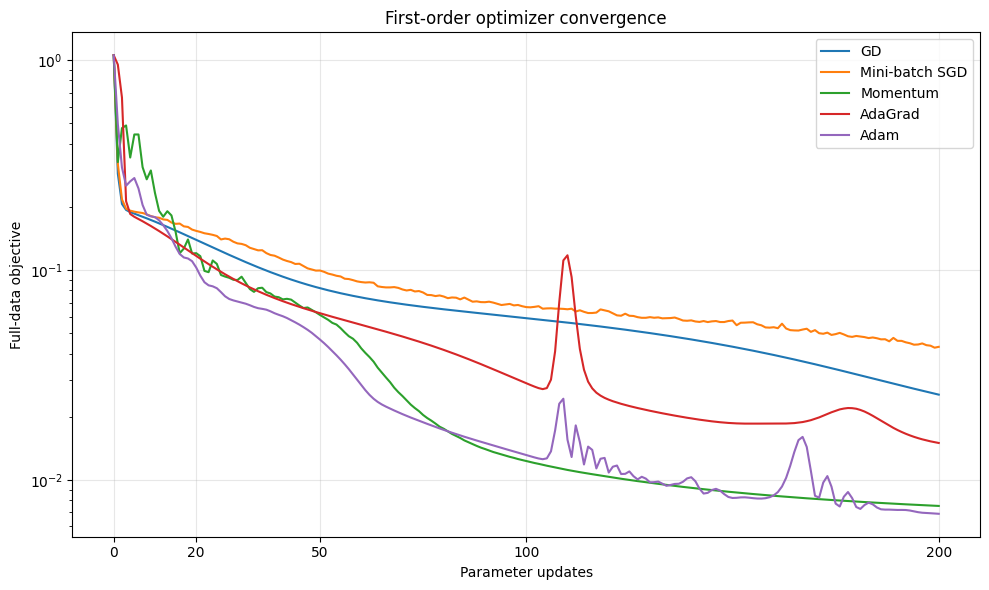

In [180]:
plt.figure(figsize=(10, 6))

for method, result in first_order_results.items():
    plt.plot(
        range(len(result["history"])),
        result["history"],
        label=method
    )

plt.xlabel("Parameter updates")
plt.ylabel("Full-data objective")
plt.title("First-order optimizer convergence")
plt.xticks(CHECKPOINTS)
plt.yscale("log")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

nn_results.update(first_order_results)

---
# Results, Comparisons, and Discussion

Submit a comparison table and a convergence plot for each problem. Include hyperparameter-search information (which settings you tried and how you selected the final settings), **not just the best run**.

### Problem 1 — Convex Portfolio

| Required method | Best hyperparameters | Objective @ 20 | @ 50 | @ 100 | Feasible @ 100? | Violations | Time / evaluations |
|---|---|---:|---:|---:|---|---|---|
| Manual PGD | | | | | | | |
| Projected Momentum | | | | | | | |
| Projected Adam | | | | | | | |
| SciPy constrained solver | | | | | | | |
| Squared-penalty method | | | | | | | |

### Problem 2 — Nonconvex Model Fitting

| Required method | Best hyperparameters | Objective @ 20 | @ 50 | @ 100 | @ 200 | Time / evaluations |
|---|---|---:|---:|---:|---:|---|
| Full-batch GD | lr=0.4 |0.139204 |0.081910 |0.059011 |0.025483 |0.3283s / 200 |
| Mini-batch SGD |lr=0.3, B=256 |0.153556 |0.099428 |0.066556 |0.043050 |0.1500s / 200 |
| Momentum |lr=0.3, m=0.9 |0.120244 |0.061071 |0.012307 |0.007518 |0.1116s / 200 |
| AdaGrad |lr=0.14, acc=0 |0.116661 |0.062238 |0.028878 |0.014995 |0.1243s / 200 |
| Adam |lr=0.05, β=(0.85, 0.999) |0.102725 |0.046612 |0.013132 |0.006897 |0.1305s / 200 |
| PyTorch L-BFGS | | | | | | |
| SciPy BFGS | | | | | | |

### Discussion questions

1. **Manual implementation:** Describe how you implemented PGD, including the projection and stopping/monitoring logic. How did you verify correctness?
2. **Convex portfolio:** Which approach achieves the lowest **feasible** objective within 100 iterations? How does the penalty method trade off objective improvement and constraint violation?
3. **Nonconvex objective:** Which optimizer achieves the lowest full-data objective after 200 updates? Which hyperparameters mattered most? Did different methods show different convergence patterns?
4. **Budget fairness:** Compare iterations, objective/gradient evaluations, and wall-clock time. Why do these measures give different perspectives on efficiency?
5. **Practical choice:** Which built-in method would you use for each problem in practice, and when is a custom implementation justified?

**Evaluation:** Compare the **feasible original objective after a fixed iteration budget** for the projected first-order portfolio methods, and the **full original objective after the fixed update budget** for the nonconvex problem. Dedicated constrained solvers provide a portfolio accuracy benchmark; penalty methods also receive a feasibility analysis. Correct manual implementation, comprehensive comparisons, tuning, reproducibility, and explanations are all required.
